# Mechanical separations: Ruth filtration, thickener area and a dryer-exhaust cyclone

`difflow.units.mechanical` has the `Settler`, `CakeFilter` and `Cyclone` units and the library behind them.
This notebook (1) fits a Ruth plot, (2) finds the optimal filter cycle by gradient, (3) sizes a thickener
and (4) puts a cyclone on a dryer exhaust.

**All data here are synthetic and illustrative.** No textbook worked example (Geankoplis Ch. 14, McCabe Ch. 29-30,
Cooper & Alley Ch. 4) is reproduced: their numbers could not be recalled with confidence. The Lapple constants
(K = 16, the standard proportions) are from memory and unverified. Centrifuges (Sigma theory) are in `difflow_bio`.

In [1]:
import math
import jax, jax.numpy as jnp, numpy as np
import matplotlib.pyplot as plt
jax.config.update("jax_enable_x64", True)
from difflow import (CakeFilter, CakeFilterParams, Cyclone, CycloneParams, Settler, SettlerParams, Dryer, DryerParams,
                     fit_ruth, ruth_constants, ruth_constant_pressure, cycle_throughput, optimal_cycle,
                     thickener_area_coe_clevenger, dust_laden_gas, lapple_efficiency)
from difflow.psychrometrics import MW_WATER, air_stream_from_state, state

## 1. The Ruth plot from data

Constant-pressure filtration: $t/V = (K_p/2)V + B$. We generate noisy data from known constants (area 0.0439 m$^2$,
$\Delta P$ = 267 kPa, $\alpha = 3\times10^{10}$ m/kg, $R_m = 6\times10^{9}$ 1/m; synthetic) and recover them.

alpha = 3.012e+10 (true 3.0e+10), R_m = 6.007e+09 (true 6.0e+09), R^2 = 0.9995


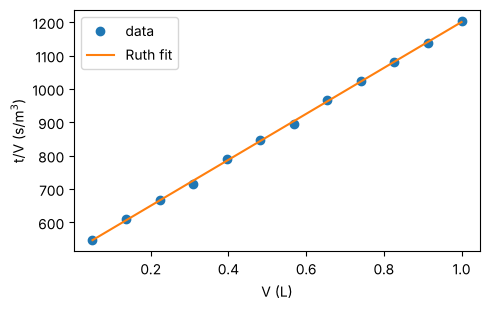

In [2]:
A, dP, mu, c_s, alpha_true, Rm_true = 0.0439, 267e3, 1.0e-3, 23.5, 3.0e10, 6.0e9
K_p, B = ruth_constants(A, dP, mu, alpha_true, c_s, Rm_true)
V = jnp.linspace(0.05, 1.0, 12) * 1e-3
rng = np.random.default_rng(1)
t = ruth_constant_pressure(V, K_p, B) * (1 + 0.01 * rng.standard_normal(V.size))
fit = fit_ruth(t, V, A=A, dP=dP, mu=mu, c_s=c_s)
print(f"alpha = {float(fit['alpha']):.3e} (true {alpha_true:.1e}), R_m = {float(fit['R_m']):.3e} (true {Rm_true:.1e}), R^2 = {float(fit['r2']):.4f}")
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(np.asarray(V) * 1e3, np.asarray(t / V), "o", label="data")
ax.plot(np.asarray(V) * 1e3, np.asarray(fit["slope"] * V + fit["intercept"]), label="Ruth fit")
ax.set_xlabel("V (L)"); ax.set_ylabel("t/V (s/m$^3$)"); ax.legend(); fig.tight_layout()

## 2. The optimal cycle by gradient

A press cycle is filtration, wash (0.2 filtrate volumes at the final rate) and 700 s downtime. The throughput
$V/(t_f+t_w+t_d)$ is differentiable in $t_f$, so `jax.grad` finds the maximum; it equals the closed form
$\tfrac{K_p}{2}(1+2r/\phi)V^2 = t_d$.

Newton on the gradient: t_f = 524.49 s, closed form 524.49 s


optimum throughput 20.6 m^3/h, d(throughput)/d(t_f) there = -8.5e-22


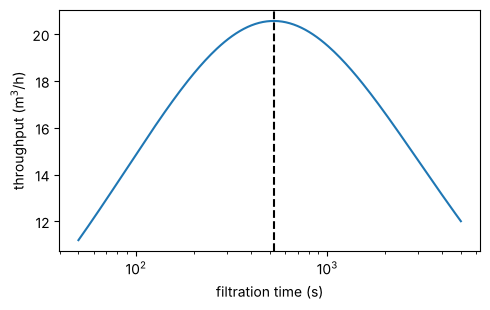

In [3]:
K_p, B, t_d, r = 15.0, 3.0, 700.0, 0.2
opt = optimal_cycle(K_p, B, t_d, wash_ratio=r)
tf = jnp.exp(jnp.linspace(math.log(50.0), math.log(5000.0), 200))
thr = jax.vmap(lambda x: cycle_throughput(x, K_p, B, t_d, r))(tf)
# Newton iteration on log t_f using jax.grad and jax.hessian of the throughput
obj = lambda lt: cycle_throughput(jnp.exp(lt), K_p, B, t_d, r) * 1e3
g, h = jax.jit(jax.grad(obj)), jax.jit(jax.hessian(obj))
lt = jnp.log(300.0)
for _ in range(30):
    lt = lt - g(lt) / h(lt)
print(f"Newton on the gradient: t_f = {float(jnp.exp(lt)):.2f} s, closed form {float(opt['t_f']):.2f} s")
print(f"optimum throughput {float(opt['throughput']) * 3600:.1f} m^3/h, d(throughput)/d(t_f) there = "
      f"{float(jax.grad(cycle_throughput)(opt['t_f'], K_p, B, t_d, r)):.1e}")
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.semilogx(np.asarray(tf), np.asarray(thr) * 3600); ax.axvline(float(opt["t_f"]), ls="--", c="k")
ax.set_xlabel("filtration time (s)"); ax.set_ylabel("throughput (m$^3$/h)"); fig.tight_layout()

## 3. A thickener area

A synthetic settling law $v(C) = v_0 (C_0/C)^2$ (illustrative). The Coe-Clevenger area is
$F_s\max_C (1/C - 1/C_u)/v$ with a smooth log-sum-exp maximum; here the maximum is at $C_u/2$ with the closed form
$Q_0 C_u/(4 v_0 C_0)$. The `Settler` does the same from the particle model.

In [4]:
Q0, C0, Cu, v0 = 0.20, 20.0, 100.0, 2.0e-4
Cg = jnp.linspace(C0, Cu, 400)
A_smooth = thickener_area_coe_clevenger(Q0, C0, Cu, Cg, v0 * (C0 / Cg) ** 2, 1000.0)
print(f"smooth-max (sharpness 1000) area {float(A_smooth):.2f} m^2, closed form {Q0 * Cu / (4 * v0 * C0):.2f} m^2")
print("d(area)/d(C_u) =", float(jax.grad(lambda cu: thickener_area_coe_clevenger(
    Q0, C0, cu, C0 + (cu - C0) * jnp.linspace(0, 1, 400), v0 * (C0 / (C0 + (cu - C0) * jnp.linspace(0, 1, 400))) ** 2, 1000.0))(Cu)), "m^2 per kg/m^3")
feed = {"F_solid": 5.0, "F_H2O": 50000.0 / 18.015, "T": 300.0, "P": 101325.0}
_, under, info = Settler(SettlerParams(underflow_concentration=300.0, d_p=25e-6, rho_p=2650.0,
                                      richardson_zaki_n=4.65, safety_factor=1.25))(feed)
print(f"particle model: required {float(info['area_required']):.1f} m^2, design {float(info['area']):.1f} m^2, "
      f"limiting concentration {float(info['limiting_concentration']):.1f} kg/m^3")

smooth-max (sharpness 1000) area 1252.32 m^2, closed form 1250.00 m^2


d(area)/d(C_u) = 12.519866004563735 m^2 per kg/m^3


particle model: required 75.4 m^2, design 94.3 m^2, limiting concentration 96.2 kg/m^3


## 4. A cyclone on a dryer exhaust

`Dryer(entrainment=0.05)` puts 5 % of the dry solid in `info["fines"]`, not in `air_out`;
`dust_laden_gas` merges them for the cyclone (synthetic numbers).

d50 = 8.5 um, grade efficiency [0.052 0.257 0.58  0.847 0.972]
overall efficiency 0.582, dP = 1618 Pa, v_i = 19.8 m/s
solid: product 0.4750 + collected 0.0146 + escaping 0.0104 kg/s


d(efficiency)/dD = -0.237 per m (a smaller cyclone collects more, at a higher dP)


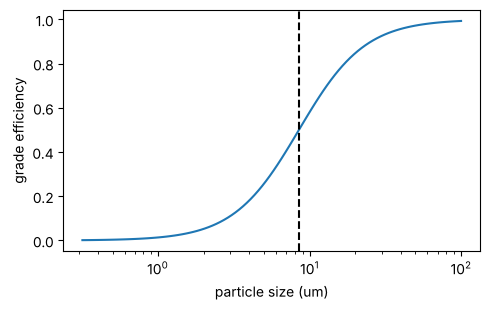

In [5]:
wet = {"F_solid": 0.5, "F_H2O": 0.5 * 0.30 / MW_WATER, "T": 300.0, "P": 101325.0}
air = air_stream_from_state(state(T=373.15, W=0.01), 10.0)
dryer = Dryer(DryerParams(mode="continuous", X_c=0.15, X_eq=0.02, product_moisture=0.05, h=60.0,
                          solids_per_area=10.0, max_solids_T=340.0, entrainment=0.05))
dry, air_out, dinfo = dryer(wet, air)
inlet = dust_laden_gas(air_out, dinfo["fines"])
bins = [2e-6, 5e-6, 10e-6, 20e-6, 50e-6]
cyc = lambda D: Cyclone(CycloneParams(D=D, rho_p=1500.0, gas_MW=28.5, d_bins=bins, mass_fractions=[0.1, 0.2, 0.3, 0.3, 0.1]))(inlet)
clean, dust, ci = cyc(2.0)
print(f"d50 = {float(ci['d50']) * 1e6:.1f} um, grade efficiency {np.round(np.asarray(ci['grade_efficiency']), 3)}")
print(f"overall efficiency {float(ci['overall_efficiency']):.3f}, dP = {float(ci['delta_P']):.0f} Pa, v_i = {float(ci['inlet_velocity']):.1f} m/s")
print(f"solid: product {float(dry['F_solid']):.4f} + collected {float(dust['F_solid']):.4f} + escaping {float(clean['F_solid']):.4f} kg/s")
dD = jax.grad(lambda D: cyc(D)[2]["overall_efficiency"])(2.0)
print(f"d(efficiency)/dD = {float(dD):.3f} per m (a smaller cyclone collects more, at a higher dP)")
d = np.logspace(-6.5, -4, 100)
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.semilogx(d * 1e6, np.asarray(lapple_efficiency(d, ci["d50"]))); ax.axvline(float(ci["d50"]) * 1e6, ls="--", c="k")
ax.set_xlabel("particle size (um)"); ax.set_ylabel("grade efficiency"); fig.tight_layout()